In [ ]:
# connecte Google Drive à l'environnement Colab, pour accéder aux fichiers stockés dans le Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os  # bibliothèque pour interagir avec le système de fichiers

DATASET_PATH = '/content/drive/MyDrive/dataset2'  # chemin du dataset sur Drive

# Liste tous les sous-dossiers de dataset2 (un sous-dossier = une classe)
classes = os.listdir(DATASET_PATH)

print(f"Nombre de classes : {len(classes)}")  # affiche le nombre total de classes détectées
print(f"Classes : {classes}")                 # affiche le nom de chaque classe (A, B, ..., 0, 1, ...)

Nombre de classes : 36
Classes : ['X', 'W', 'Z', 'Y', 'V', 'S', 'R', 'U', 'Q', 'T', 'P', 'O', 'K', 'N', 'M', 'L', 'J', 'I', 'F', '8', 'B', 'H', 'A', 'D', '9', 'G', 'C', '7', '6', 'E', '5', '4', '2', '3', '1', '0']


In [ ]:
import os
import json
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [ ]:
from scipy.interpolate import interp1d

DATASET_PATH    = '/content/drive/MyDrive/dataset2'  # ← dataset2 au lieu de dataset
SEQUENCE_LENGTH = 30  # longueur cible fixe après normalisation

X, y = [], []  # X = séquences de coordonnées, y = étiquettes correspondantes

def normaliser_sequence(sequence, longueur_cible=30):
    """
    Normalise une séquence à une longueur fixe par interpolation.
    Quelle que soit la longueur originale, la séquence sera
    ramenée à 'longueur_cible' points.
    """
    sequence = np.array(sequence)  # convertir en tableau numpy
    n = len(sequence)              # longueur originale

    # Si la séquence est trop courte (moins de 2 points), on l'ignore
    if n < 2:
        return None

    # Créer les indices originaux et cibles
    indices_originaux = np.linspace(0, 1, n)
    indices_cibles    = np.linspace(0, 1, longueur_cible)

    # Interpoler x et y séparément
    interp_x = interp1d(indices_originaux, sequence[:, 0])
    interp_y = interp1d(indices_originaux, sequence[:, 1])

    # Retourner la séquence normalisée
    x_norm = interp_x(indices_cibles)
    y_norm = interp_y(indices_cibles)

    return np.column_stack([x_norm, y_norm])

# Parcourir chaque classe (lettre, chiffre, forme)
for label in os.listdir(DATASET_PATH):
    label_dir = os.path.join(DATASET_PATH, label)

    # Parcourir chaque fichier JSON de la classe
    for fichier in os.listdir(label_dir):
        filepath = os.path.join(label_dir, fichier)
        try:
            # Lire le fichier JSON contenant la trajectoire
            with open(filepath, 'r') as f:
                data = json.load(f)

            sequence = data['sequence']

            # Normaliser la séquence à 30 frames par interpolation
            sequence_normalisee = normaliser_sequence(sequence, SEQUENCE_LENGTH)

            if sequence_normalisee is not None:
                X.append(sequence_normalisee)  # ajouter la trajectoire normalisée
                y.append(label)               # ajouter l'étiquette correspondante

        except Exception as e:
            # Ignorer les fichiers corrompus et continuer
            print(f"Fichier ignoré : {fichier} → {e}")
            continue

# Convertir en tableaux numpy
X = np.array(X)  # shape finale : (nb_echantillons, 30, 2)
print(f"Forme de X              : {X.shape}")
print(f"Nombre total d'échantillons : {len(y)}")

Forme de X              : (1078, 30, 2)
Nombre total d'échantillons : 1078


In [ ]:
def augmenter_sequence(sequence):
    """
    Génère plusieurs versions modifiées d'une séquence existante.
    Simule la variabilité naturelle entre utilisateurs.
    """
    augmentees = []
    sequence = np.array(sequence)

    # 1. Bruit gaussien léger : simule les tremblements de main
    bruit = sequence + np.random.normal(0, 0.01, sequence.shape)
    augmentees.append(bruit)

    # 2. Mise à l'échelle : simule les différences de taille de geste
    echelle = sequence * np.random.uniform(0.85, 1.15)
    augmentees.append(echelle)

    # 3. Translation : simule les différences de position dans l'espace
    translation = sequence + np.random.uniform(-0.05, 0.05, sequence.shape)
    augmentees.append(translation)

    # 4. Bruit + échelle combinés
    combine = sequence * np.random.uniform(0.9, 1.1) + np.random.normal(0, 0.008, sequence.shape)
    augmentees.append(combine)

    # 5. Légère rotation autour du centre
    angle = np.random.uniform(-10, 10) * np.pi / 180  # angle en radians
    centre = sequence.mean(axis=0)
    seq_centre = sequence - centre
    matrice_rotation = np.array([
        [np.cos(angle), -np.sin(angle)],
        [np.sin(angle),  np.cos(angle)]
    ])
    rotee = seq_centre @ matrice_rotation.T + centre
    augmentees.append(rotee)

    return augmentees

# Appliquer l'augmentation sur tout le dataset
X_aug, y_aug = list(X), list(y)  # copie des données originales

for i in range(len(X)):
    versions = augmenter_sequence(X[i])
    for version in versions:
        X_aug.append(version)
        y_aug.append(y[i])

X_aug = np.array(X_aug)
y_aug = np.array(y_aug)

print(f"Avant augmentation : {len(X)} échantillons")
print(f"Après augmentation : {len(X_aug)} échantillons")
print(f"Facteur d'augmentation : x{len(X_aug)//len(X)}")

Avant augmentation : 1078 échantillons
Après augmentation : 6468 échantillons
Facteur d'augmentation : x6


Encoder les classes

In [ ]:
# LabelEncoder convertit les étiquettes texte en chiffres
# ex : 'A' → 0, 'B' → 1, 'cercle' → 10, etc.
encoder       = LabelEncoder()
y_encoded     = encoder.fit_transform(y_aug)  # ← y_aug au lieu de y

# to_categorical convertit en one-hot encoding
# ex : 0 → [1,0,0,...], 1 → [0,1,0,...], etc.
y_categorical = to_categorical(y_encoded)

print(f"Classes encodées  : {list(encoder.classes_)}")
print(f"Nombre de classes : {len(encoder.classes_)}")

Classes encodées  : [np.str_('0'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6'), np.str_('7'), np.str_('8'), np.str_('9'), np.str_('A'), np.str_('B'), np.str_('C'), np.str_('D'), np.str_('E'), np.str_('F'), np.str_('G'), np.str_('H'), np.str_('I'), np.str_('J'), np.str_('K'), np.str_('L'), np.str_('M'), np.str_('N'), np.str_('O'), np.str_('P'), np.str_('Q'), np.str_('R'), np.str_('S'), np.str_('T'), np.str_('U'), np.str_('V'), np.str_('W'), np.str_('X'), np.str_('Y'), np.str_('Z')]
Nombre de classes : 36


In [ ]:
# 80% des données pour l'entraînement, 20% pour le test
X_train, X_test, y_train, y_test = train_test_split(
    X_aug, y_categorical,  # ← X_aug au lieu de X
    test_size=0.2,         # 20% pour le test
    random_state=42        # graine pour la reproductibilité
)

print(f"Taille Train : {X_train.shape}")
print(f"Taille Test  : {X_test.shape}")

Taille Train : (5174, 30, 2)
Taille Test  : (1294, 30, 2)


 Construire le modèle LSTM

In [ ]:
model = Sequential([
    # Première couche LSTM : 64 unités, retourne toute la séquence
    # input_shape = (30 frames, 2 coordonnées x,y)
    LSTM(64, return_sequences=True, input_shape=(SEQUENCE_LENGTH, 2)),
    Dropout(0.2),   # désactive 20% des neurones pour éviter le surapprentissage

    # Deuxième couche LSTM : 128 unités, retourne uniquement le dernier état
    LSTM(128),
    Dropout(0.2),   # désactive 20% des neurones pour éviter le surapprentissage

    # Couche dense intermédiaire pour affiner la classification
    Dense(64, activation='relu'),

    # Couche de sortie : un neurone par classe, softmax donne les probabilités
    Dense(len(encoder.classes_), activation='softmax')
])

# Compilation du modèle
# adam      : optimiseur adaptatif efficace pour les RNN
# categorical_crossentropy : fonction de perte pour classification multi-classes
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Afficher le résumé de l'architecture
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,564 (494.39 KB)

 Trainable params: 126,564 (494.39 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    # Arrête l'entraînement si la performance ne s'améliore plus après 10 epochs
    EarlyStopping(patience=10, restore_best_weights=True),

    # Sauvegarde automatiquement le meilleur modèle dans Drive
    ModelCheckpoint(
        '/content/drive/MyDrive/model_airwriting.h5',
        save_best_only=True
    )
]

In [ ]:
# Lancement de l'entraînement
history = model.fit(
    X_train, y_train,
    epochs=100,          # nombre maximum d'itérations
    batch_size=32,       # nombre d'échantillons traités à la fois
    validation_data=(X_test, y_test),  # données de validation
    callbacks=callbacks
)

Epoch 1/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.0787 - loss: 3.3447

162/162 ━━━━━━━━━━━━━━━━━━━━ 16s 72ms/step - accuracy: 0.1494 - loss: 2.9347 - val_accuracy: 0.3037 - val_loss: 2.1844
Epoch 2/100
161/162 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3707 - loss: 1.9196

162/162 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.4254 - loss: 1.7530 - val_accuracy: 0.5757 - val_loss: 1.3378
Epoch 3/100
161/162 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5868 - loss: 1.3115

162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.6281 - loss: 1.1851 - val_accuracy: 0.6530 - val_loss: 1.0496
Epoch 4/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6814 - loss: 1.0087

162/162 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.7095 - loss: 0.9080 - val_accuracy: 0.7388 - val_loss: 0.7820
Epoch 5/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.7782 - loss: 0.7423

162/162 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - accuracy: 0.7855 - loss: 0.7085 - val_accuracy: 0.8099 - val_loss: 0.6041
Epoch 6/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8291 - loss: 0.5448

... (11 outputs left out)

162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 74ms/step - accuracy: 0.9755 - loss: 0.0805 - val_accuracy: 0.9861 - val_loss: 0.0371
Epoch 23/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.9874 - loss: 0.0468 - val_accuracy: 0.9853 - val_loss: 0.0421
Epoch 24/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.9675 - loss: 0.1002 - val_accuracy: 0.9784 - val_loss: 0.0721
Epoch 25/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.9596 - loss: 0.1347 - val_accuracy: 0.9776 - val_loss: 0.0653
Epoch 26/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9836 - loss: 0.0568 - val_accuracy: 0.9807 - val_loss: 0.0516
Epoch 27/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.9778 - loss: 0.0676 - val_accuracy: 0.9760 - val_loss: 0.0600
Epoch 28/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.9859 - loss: 0.0471 - val_accuracy: 0.9853 - val_loss: 0.0584
Epoch 29/100
161/162 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9894 - loss: 0.0384

162/162 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - accuracy: 0.9911 - loss: 0.0349 - val_accuracy: 0.9930 - val_loss: 0.0218
Epoch 30/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 18s 64ms/step - accuracy: 0.9789 - loss: 0.0702 - val_accuracy: 0.9567 - val_loss: 0.1117
Epoch 31/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9764 - loss: 0.0666 - val_accuracy: 0.9900 - val_loss: 0.0318
Epoch 32/100
161/162 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9864 - loss: 0.0461

162/162 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.9878 - loss: 0.0403 - val_accuracy: 0.9961 - val_loss: 0.0117
Epoch 33/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.9872 - loss: 0.0397 - val_accuracy: 0.9853 - val_loss: 0.0508
Epoch 34/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.9869 - loss: 0.0463 - val_accuracy: 0.9714 - val_loss: 0.0768
Epoch 35/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 22s 76ms/step - accuracy: 0.9818 - loss: 0.0542 - val_accuracy: 0.9699 - val_loss: 0.0988
Epoch 36/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.9782 - loss: 0.0683 - val_accuracy: 0.9861 - val_loss: 0.0432
Epoch 37/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.9859 - loss: 0.0463 - val_accuracy: 0.9869 - val_loss: 0.0433
Epoch 38/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.9925 - loss: 0.0228 - val_accuracy: 0.9923 - val_loss: 0.0175
Epoch 39/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9936 - loss: 0.0216

162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step - accuracy: 0.9950 - loss: 0.0173 - val_accuracy: 0.9985 - val_loss: 0.0076
Epoch 40/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.9871 - loss: 0.0471 - val_accuracy: 0.9869 - val_loss: 0.0438
Epoch 41/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step - accuracy: 0.9874 - loss: 0.0409 - val_accuracy: 0.9915 - val_loss: 0.0240
Epoch 42/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9917 - loss: 0.0322 - val_accuracy: 0.9853 - val_loss: 0.0425
Epoch 43/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9913 - loss: 0.0280 - val_accuracy: 0.9853 - val_loss: 0.0334
Epoch 44/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.9876 - loss: 0.0423 - val_accuracy: 0.9923 - val_loss: 0.0289
Epoch 45/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9853 - loss: 0.0469 - val_accuracy: 0.9799 - val_loss: 0.0547
Epoch 46/100
162/162 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.9766 - loss: 0.0729 

In [ ]:
import pickle

# 1. Sauvegarder le modèle entraîné
model.save("modele_air_writing.keras")   # format Keras natif recommandé
# Alternative compatible plus large : model.save("modele_air_writing.h5")

# 2. Sauvegarder l'historique d'entraînement (pour retracer les courbes sans réentraîner)
with open("history_air_writing.pkl", "wb") as f:
    pickle.dump(history.history, f)

print("Modèle et historique sauvegardés avec succès.")

Modèle et historique sauvegardés avec succès.


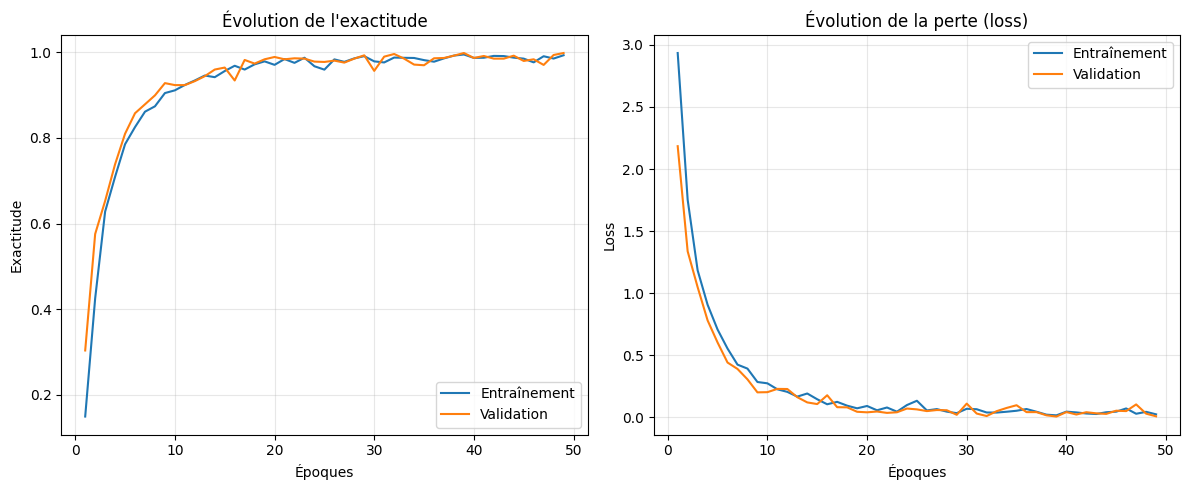

In [ ]:
#Visualisation des  Courbes d'apprentissage
import matplotlib.pyplot as plt

def plot_learning_curves(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(epochs_range, acc, label="Entraînement")
    axes[0].plot(epochs_range, val_acc, label="Validation")
    axes[0].set_title("Évolution de l'exactitude")
    axes[0].set_xlabel("Époques")
    axes[0].set_ylabel("Exactitude")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs_range, loss, label="Entraînement")
    axes[1].plot(epochs_range, val_loss, label="Validation")
    axes[1].set_title("Évolution de la perte (loss)")
    axes[1].set_xlabel("Époques")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("courbes_apprentissage.png", dpi=300)
    plt.show()

plot_learning_curves(history)

In [ ]:
# Évaluation finale sur les données de test
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Loss     : {loss:.4f}")
print(f"Accuracy : {accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9985 - loss: 0.0076
Loss     : 0.0076
Accuracy : 99.85%


41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


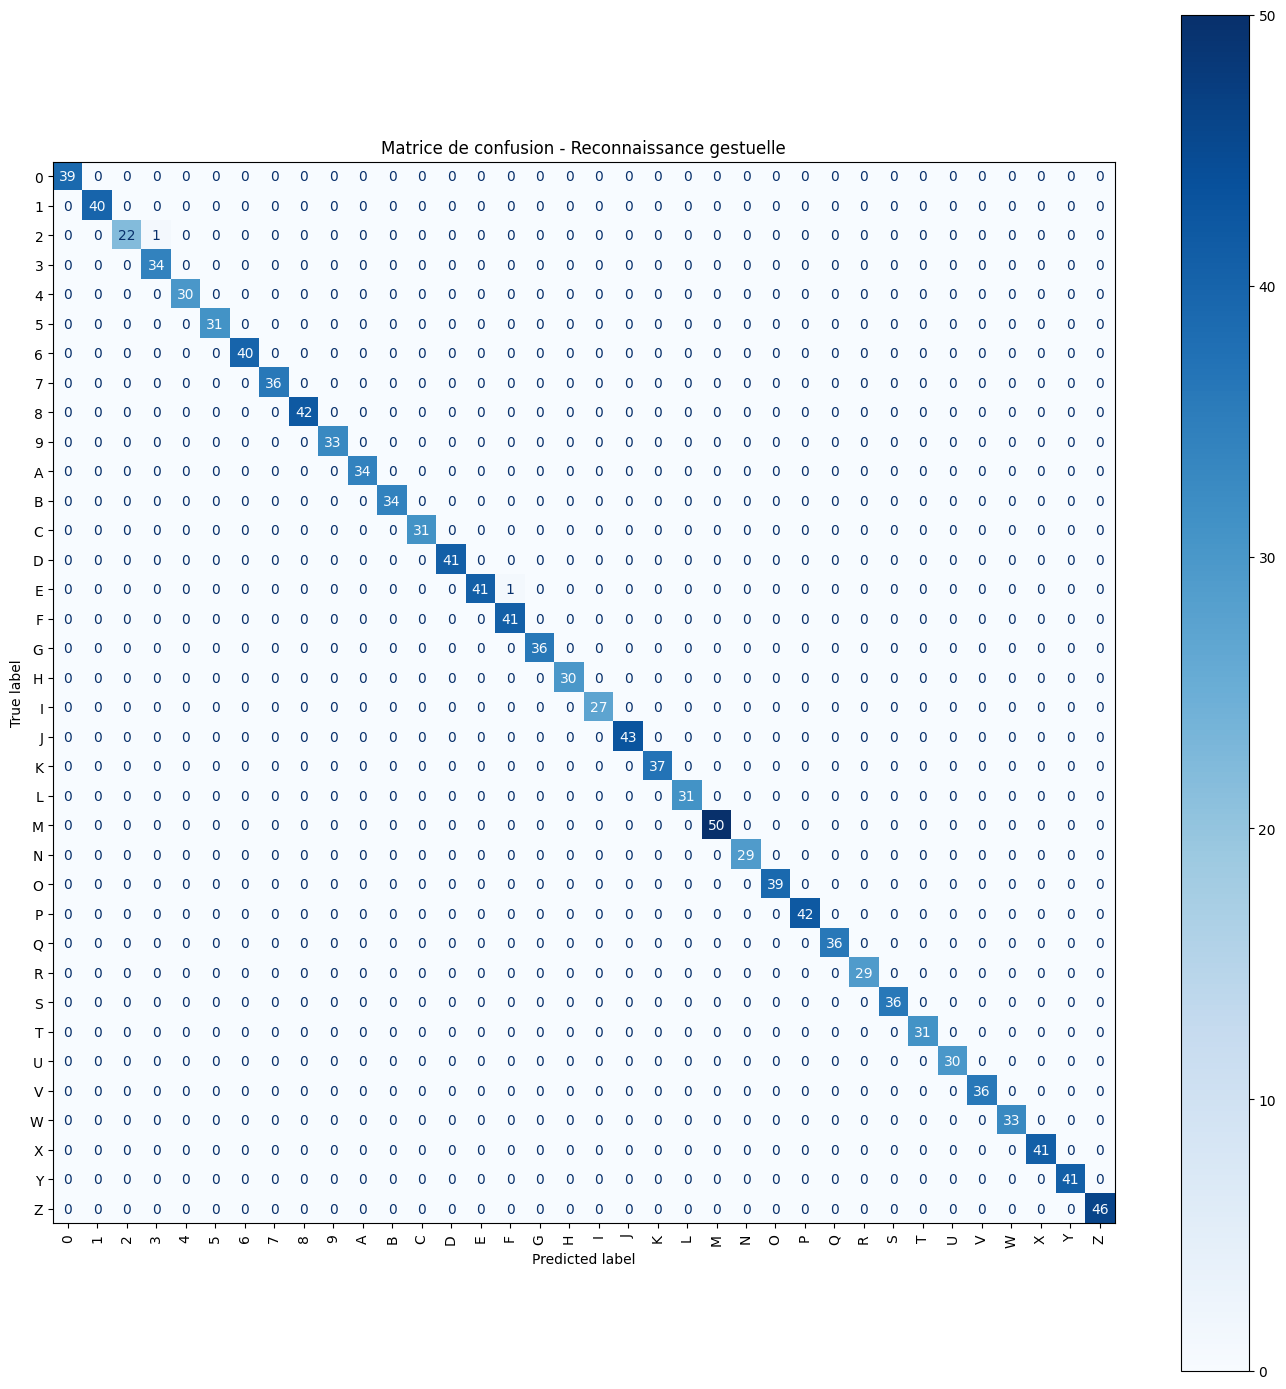

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# confusion_matrix : calcule la matrice de confusion
# ConfusionMatrixDisplay : permet d'afficher cette matrice sous forme de graphique

# Prédire les probabilités pour chaque classe sur l'ensemble de test
y_pred_probs = model.predict(X_test)

# Convertir les probabilités en indices de classe (la classe avec la plus forte probabilité)
y_pred = np.argmax(y_pred_probs, axis=1)

# Convertir les étiquettes réelles (one-hot encoding) en indices de classe
y_true = np.argmax(y_test, axis=1)

# Récupérer les noms réels des classes (A, B, ..., 0, 1, ...) depuis l'encodeur
class_names = encoder.classes_   # ✅ corrigé

# Calculer la matrice de confusion : compare prédictions vs vraies étiquettes
cm = confusion_matrix(y_true, y_pred)

# Créer la figure (grande taille pour bien lire les 36 classes)
fig, ax = plt.subplots(figsize=(14, 14))

# Préparer l'affichage de la matrice avec les noms de classes en légende
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Afficher la matrice : couleur bleue, étiquettes x pivotées à 90°, avec barre de couleur
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=True)

plt.title("Matrice de confusion - Reconnaissance gestuelle")  # titre du graphique
plt.tight_layout()                                             # ajuste les marges automatiquement
plt.savefig("matrice_confusion.png", dpi=300)                  # sauvegarde l'image en haute résolution
plt.show()                                                      # affiche le graphique

In [ ]:
import pickle

# Sauvegarder l'encodeur pour pouvoir l'utiliser lors de la reconnaissance
with open('/content/drive/MyDrive/label_encoder2.pkl', 'wb') as f:
    pickle.dump(encoder, f)

print("Modèle et encodeur sauvegardés dans Drive !")

Modèle et encodeur sauvegardés dans Drive !
